# Why did gross profit change? A price-volume-mix bridge for an EV maker, 2016 vs 2017
**The FP&A question.** Gross profit moved between two years. How much of the change came from selling **more or fewer cars (volume)**, selling a **different mix** of models, versions and countries (mix), and **price and unit-margin** changes, including products launched or discontinued?

**Data.** 85,592 vehicle sales (Model S and Model X, six versions, US, Germany and Australia, January 2016 to December 2017) with selling price and gross profit per car. This is a **teaching dataset**: the figures are illustrative and are not the company's reported results.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
s = pd.read_csv("data/ev_sales_2016_2017.csv.gz")
s["year"] = s.Period // 100; s["month"] = pd.to_datetime(s.Period.astype(str), format="%Y%m")
s["segment"] = s.Model + " " + s.Version + " | " + s.Country
summary = s.groupby("year").agg(units=("Price", "size"), revenue_m=("Price", lambda x: x.sum() / 1e6), gross_profit_m=("Gross Profit", lambda x: x.sum() / 1e6))
summary["gross_margin_%"] = 100 * summary.gross_profit_m / summary.revenue_m
summary["GP_per_unit"] = 1e6 * summary.gross_profit_m / summary.units
summary.round(2)

,units,revenue_m,gross_profit_m,gross_margin_%,GP_per_unit
year,,,,,
2016,43250,3253.22,949.41,29.18,21951.76
2017,42342,3187.85,928.95,29.14,21939.12


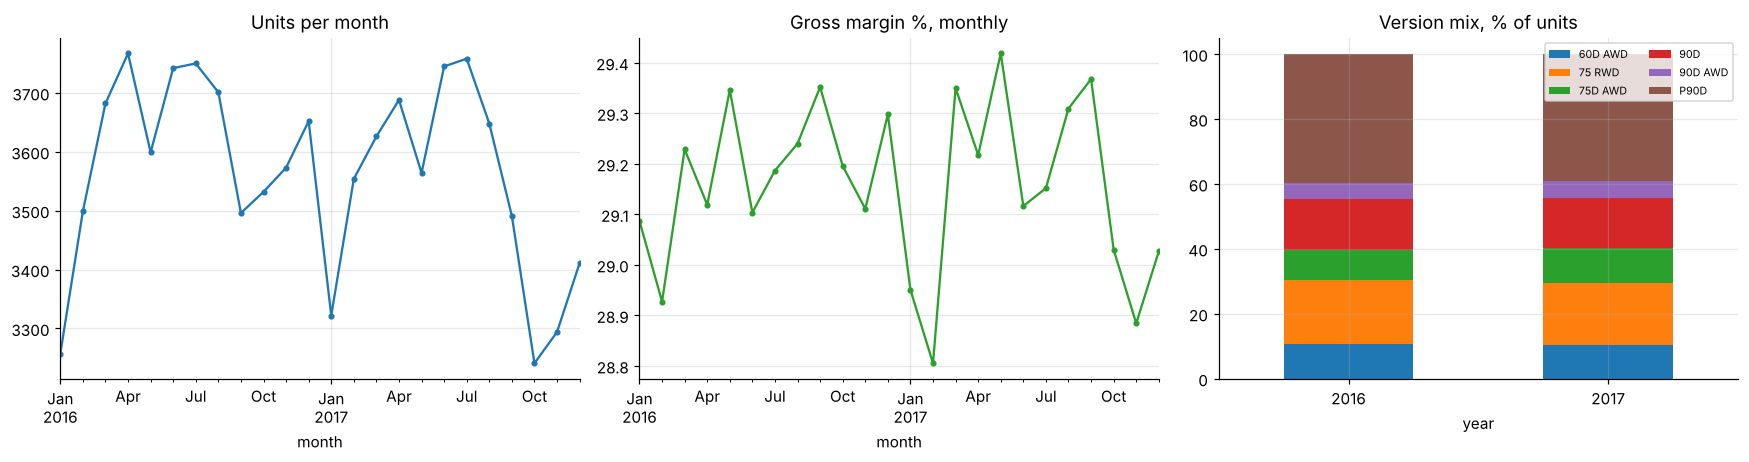

size            mean         
year              2016   2017     2016     2017
Model   Version                                
Model S 60D AWD   4611   4421  21502.0  21799.0
        75 RWD    8487   8005  17645.0  17444.0
        75D AWD   4051   4609  26192.0  26129.0
        90D AWD   2199   2242  29095.0  28266.0
Model X 90D       6765   6547  22174.0  22130.0
        P90D     17137  16518  22199.0  22052.0

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
m = s.groupby("month").agg(units=("Price", "size"), gm=("Gross Profit", "sum"), rev=("Price", "sum"))
m.units.plot(ax=axes[0], title="Units per month", marker=".")
(100 * m.gm / m.rev).plot(ax=axes[1], title="Gross margin %, monthly", marker=".", c="C2")
mix = s.pivot_table(index="year", columns="Version", values="Price", aggfunc="size").fillna(0)
(mix.div(mix.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=axes[2], rot=0, title="Version mix, % of units")
axes[2].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(IMG / "trends_mix.png", bbox_inches="tight"); plt.show()
s.pivot_table(index=["Model", "Version"], columns="year", values="Gross Profit", aggfunc=["size", "mean"]).round(0)

## The bridge
For each segment $i$ (model × version × country) with units $q$ and gross profit per unit $g$, and total units $Q$:

* **Volume** $=(Q_1-Q_0)\,\bar g_0$: the change in units at last year's average unit GP and mix
* **Mix** $=\sum_i (q_{1i}-Q_1 w_{0i})\,g_{0i}$, where $w_{0i}$ is last year's unit share: selling more of high- or low-margin segments
* **Rate (price and unit margin)** $=\sum_i q_{1i}(g_{1i}-g_{0i})$, for segments sold in both years
* **New and discontinued products:** segments that exist in only one year, shown separately so they don't distort the rate effect

The four effects add up exactly to the total change. The same decomposition is applied to revenue, with price in place of unit GP.

In [3]:
def pvm(df, value):
    g = df.groupby(["segment", "year"]).agg(q=("Price", "size"), v=(value, "mean")).unstack("year")
    q0, q1, v0, v1 = g[("q", 2016)].fillna(0), g[("q", 2017)].fillna(0), g[("v", 2016)], g[("v", 2017)]
    both = (q0 > 0) & (q1 > 0)
    Q0, Q1 = q0.sum(), q1.sum()
    base = (q0 * v0.fillna(0)).sum(); new = (q1 * v1.fillna(0)).sum()
    avg0 = (q0[both] * v0[both]).sum() / q0[both].sum()
    w0 = q0[both] / q0[both].sum()
    vol = (q1[both].sum() - q0[both].sum()) * avg0
    mixe = ((q1[both] - q1[both].sum() * w0) * v0[both]).sum()
    rate = (q1[both] * (v1[both] - v0[both])).sum()
    launched = (q1[~both & (q0 == 0)] * v1[~both & (q0 == 0)]).sum()
    dropped = -(q0[~both & (q1 == 0)] * v0[~both & (q1 == 0)]).sum()
    out = pd.Series({"2016": base, "volume": vol, "mix": mixe, "price / unit margin": rate, "new products": launched, "discontinued": dropped, "2017": new})
    assert np.isclose(out["2016"] + out.iloc[1:-1].sum(), out["2017"]), "bridge does not add up"
    return out
gp = pvm(s, "Gross Profit"); rev = pvm(s, "Price")
bridge = pd.DataFrame({"gross profit $m": gp / 1e6, "revenue $m": rev / 1e6}); bridge.round(2)

,gross profit $m,revenue $m
2016,949.41,3253.22
volume,-20.92,-71.68
mix,2.85,2.69
price / unit margin,-4.24,0.00
new products,1.84,3.63
discontinued,-0.00,-0.00
2017,928.95,3187.85


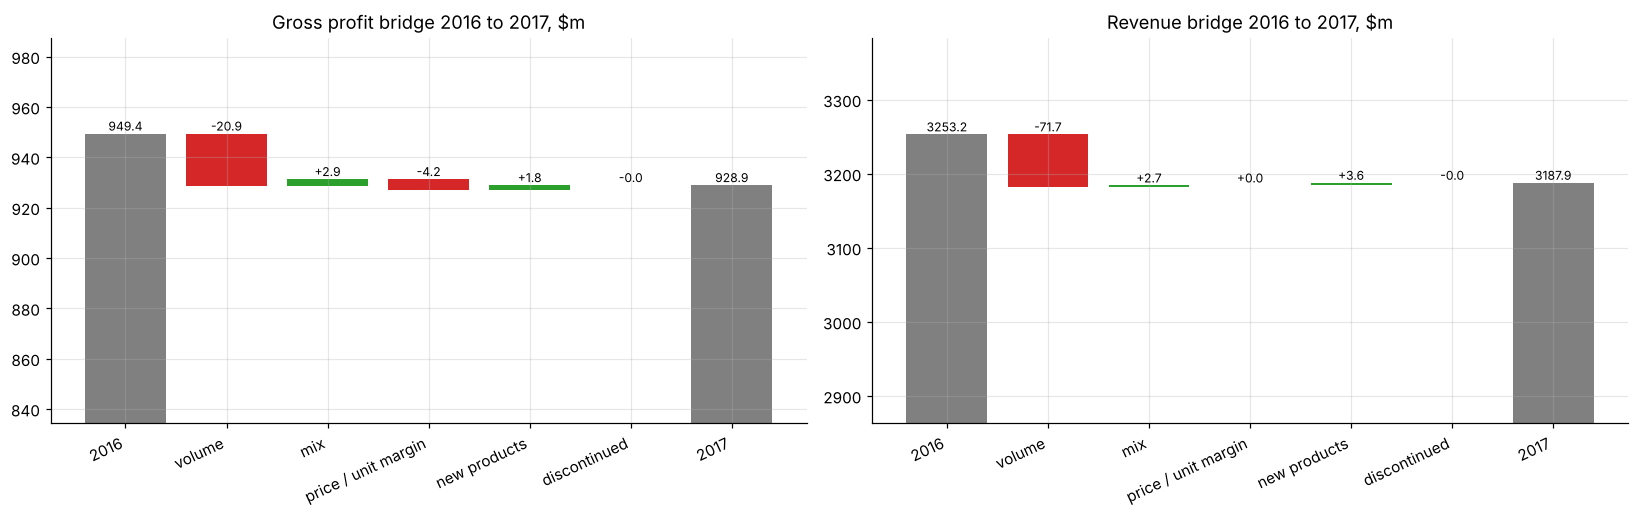

In [4]:
def waterfall(ax, ser, title):
    vals = ser.values; labels = ser.index; cum = vals[0]; bottoms, heights, colors = [0], [vals[0]], ["grey"]
    for v in vals[1:-1]:
        bottoms.append(cum if v >= 0 else cum + v); heights.append(abs(v)); colors.append("C2" if v >= 0 else "C3"); cum += v
    bottoms.append(0); heights.append(vals[-1]); colors.append("grey")
    ax.bar(range(len(vals)), heights, bottom=bottoms, color=colors)
    for i, (b, h, v) in enumerate(zip(bottoms, heights, list(vals))): ax.text(i, b + h, f"{v:+.1f}" if 0 < i < len(vals) - 1 else f"{v:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(labels, rotation=25, ha="right"); ax.set_title(title)
    lo = min(bottoms[1:-1] + [vals[0], vals[-1]]) * 0.9; ax.set_ylim(lo, max(np.array(bottoms) + np.array(heights)) * 1.04)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
waterfall(axes[0], gp / 1e6, "Gross profit bridge 2016 to 2017, $m"); waterfall(axes[1], rev / 1e6, "Revenue bridge 2016 to 2017, $m")
plt.tight_layout(); plt.savefig(IMG / "pvm_bridge.png", bbox_inches="tight"); plt.show()

In [5]:
seg = s.groupby(["Model", "Version", "year"]).agg(units=("Price", "size"), price=("Price", "mean"), gp_unit=("Gross Profit", "mean")).unstack("year")
seg.columns = [f"{a}_{b}" for a, b in seg.columns]
seg["margin_2016_%"] = 100 * seg.gp_unit_2016 / seg.price_2016; seg["margin_2017_%"] = 100 * seg.gp_unit_2017 / seg.price_2017
seg.round(1)

units_2016  units_2017  price_2016  price_2017  gp_unit_2016  gp_unit_2017  margin_2016_%  margin_2017_%
Model   Version                                                                                                          
Model S 60D AWD        4611        4421     74200.0     74200.0       21501.8       21799.5           29.0           29.4
        75 RWD         8487        8005     70700.0     70700.0       17645.3       17444.0           25.0           24.7
        75D AWD        4051        4609     75700.0     75700.0       26192.0       26128.9           34.6           34.5
        90D AWD        2199        2242     88700.0     88700.0       29095.1       28265.6           32.8           31.9
Model X 90D            6765        6547     80000.0     80000.0       22174.3       22129.6           27.7           27.7
        P90D          17137       16518     74000.0     74000.0       22198.7       22051.7           30.0           29.8

In [6]:
cty = s.groupby(["Country", "year"]).agg(units=("Price", "size"), gp_m=("Gross Profit", lambda x: x.sum() / 1e6)).unstack("year")
cty["unit_growth_%"] = 100 * (cty[("units", 2017)] / cty[("units", 2016)] - 1)
dep = s.groupby(["year", "Purchase type"]).size().unstack(); dep["deposit_share_%"] = 100 * dep["Deposit"] / dep.sum(axis=1)
display(cty.round(2)); dep.round(1)

units           gp_m         unit_growth_%
year        2016   2017    2016    2017              
Country                                              
Australia   2632   2535   39.20   41.16         -3.69
Germany     8473   8483  136.99  137.29          0.12
US         32145  31324  773.23  750.50         -2.55

Purchase type,Cash purchase,Deposit,deposit_share_%
year,,,
2016,19987,23263,53.8
2017,19629,22713,53.6


## Findings
* **Gross profit fell $20.5m (−2.2%), from $949.4m to $928.9m, almost entirely because of volume.** 908 fewer cars cost about $20.9m at last year's average GP per car. The gross margin held at 29.1-29.2%.
* **Mix helped slightly (+$2.9m):** a shift towards the high-margin Model S 75D AWD (34.5% margin, +558 units) more than offset fewer 75 RWD sales (the lowest margin, about 25%).
* **Unit margins eroded slightly (−$4.2m) at unchanged list prices.** Per-car gross profit fell on most versions (90D AWD by about $830, P90D by about $150), pointing to higher unit costs rather than discounting. Price contributed nothing to the revenue bridge.
* **New products added $1.8m:** two Model S versions launched in Australia in 2017. Nothing was discontinued.
* **By market, the US drove the decline** (−821 units, −2.6%; GP −$22.7m). Germany was flat and Australia grew its GP despite fewer units, thanks to the new versions. The deposit vs cash split was stable at about 54% deposits.
* **For a CFO:** the issue is demand, plus a smaller cost-side margin squeeze, not pricing. The next questions are US order intake and unit cost by version. *(Teaching dataset: the figures are illustrative.)*